In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
data = {
'TV_Advertising':[230,44,17,151,180,8,57,120,8,200],
'Radio_Advertising':[37,39,45,41,10,48,32,19,2,30],
'Social_Media':[69,45,69,58,12,35,23,11,1,65],
'Sales':[22.1,10.4,9.3,18.5,12.9,7.2,11.8,13.2,4.8,19.6]
}
df = pd.DataFrame(data)
df['Response'] = np.where(df['Sales']>=12,1,0)
df.head()

,TV_Advertising,Radio_Advertising,Social_Media,Sales,Response
0,230,37,69,22.1,1
1,44,39,45,10.4,0
2,17,45,69,9.3,0
3,151,41,58,18.5,1
4,180,10,12,12.9,1


In [3]:
X = df[['TV_Advertising','Radio_Advertising','Social_Media']]
y = df['Response']

In [4]:
X_train,X_test,y_train,y_test = train_test_split(
X,y,test_size=0.3,random_state=42)

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
model = LogisticRegression()
model.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [7]:
y_prob = model.predict_proba(X_test_scaled)[:,1]

In [8]:
fpr,tpr,thresholds = roc_curve(y_test,y_prob)
auc_score = roc_auc_score(y_test,y_prob)
print("AUC:",auc_score)

AUC: nan


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1201: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


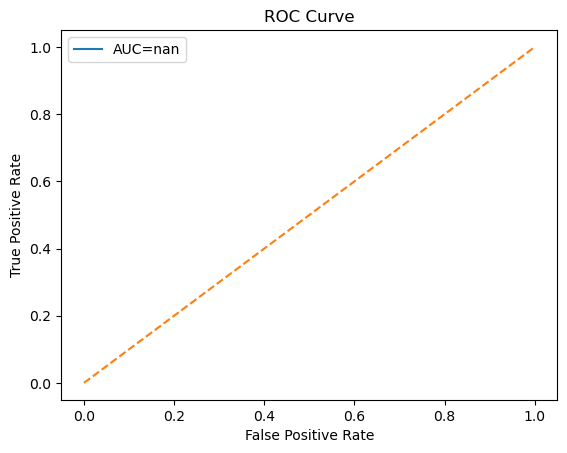

In [9]:
plt.plot(fpr,tpr,label="AUC="+str(round(auc_score,2)))
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()